In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path('../data/raw/meajor_dataset.csv') 

df = pd.read_csv(DATA_DIR)

parquet_path = Path("../data/raw/train-00000-of-00001.parquet")

df_parquet = pd.read_parquet(parquet_path)


In [2]:
df.head()

,sender,sender_domain,receiver,receiver_domain,date,subject,content_types,body,urls,url_count,url_length_max,url_length_avg,url_subdom_max,url_subdom_avg,attachment_count,has_attachments,attachment_types,language,source,label
0,d66e9e64b006d6bca649f1c945129c42c43836872b2ead...,enron.com,35c5a9fb9fba3b8737ed7cef2a87e427a73db4fca85f6b...,enron.com,2001-06-29 09:37:04-05:00,[ORGANIZATION] failover plan.,text/plain,"Hi [NAME], \n\nTonight we are rolling out a n...",NaN,0.0,0.0,0.0,0.0,0.0,0.0,False,NaN,en,trec5,0.0
1,0907d5c64598aa2639154ed4e1556be615669e40052a1f...,enron.com,aa2c35499eae5999bf6080453cc719a891da2bb0c3803d...,enron.com,2001-06-29 08:39:30-05:00,RE: Intranet Site,text/plain,"[NAME] r these new?\tIntranet Site\n\n[NAME],\...",http://eastpower.dev.corp.enron.com/summary/pj...,3.0,60.0,58.0,3.0,3.0,0.0,False,NaN,en,trec5,0.0
2,7c3201a5ff8c5985218f1e3f11e330dc0242bbd28c6c20...,enron.com,a736837579feb601fbf6c0657d3d93689774afa6491bb9...,enron.com;enron.com,2001-06-29 10:35:17-05:00,FW: [ORGANIZATION] Company information,text/plain,"[NAME]/[NAME],\n\nWe are currently trading und...",NaN,0.0,0.0,0.0,0.0,0.0,0.0,False,NaN,en,trec5,0.0
3,8531d54a169c4af106b9ea2165d4986b8cc10fc0a6bb9b...,enron.com,765a3ec4a67e40118d22de5729b05d090a1b59cb443bf6...,enron.com;enron.com,2001-06-29 10:40:02-05:00,New Master Physical,text/plain,[NAME] and [NAME] -\n\nAttached is a worksheet...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,False,NaN,en,trec5,0.0
4,7c3201a5ff8c5985218f1e3f11e330dc0242bbd28c6c20...,enron.com,ce418c97ac415706338972e1dbbd99ebb8c617b5c937a3...,enron.com;enron.com;enron.com,2001-06-29 10:48:00-05:00,FW: [ORGANIZATION]/Mirant GISB,text/plain,FYI. Below is a copy of my communication with ...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,False,NaN,en,trec5,0.0


In [3]:
df.shape

(108685, 20)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 108685 entries, 0 to 108684
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   sender            108191 non-null  str    
 1   sender_domain     108191 non-null  str    
 2   receiver          106314 non-null  str    
 3   receiver_domain   106314 non-null  str    
 4   date              108685 non-null  str    
 5   subject           107230 non-null  str    
 6   content_types     108684 non-null  str    
 7   body              108684 non-null  str    
 8   urls              64052 non-null   str    
 9   url_count         108685 non-null  float64
 10  url_length_max    108685 non-null  float64
 11  url_length_avg    108685 non-null  float64
 12  url_subdom_max    108685 non-null  float64
 13  url_subdom_avg    108685 non-null  float64
 14  attachment_count  108685 non-null  float64
 15  has_attachments   108685 non-null  bool   
 16  attachment_types  1666 non-null

In [5]:
df.isnull().sum()

sender                 494
sender_domain          494
receiver              2371
receiver_domain       2371
date                     0
subject               1455
content_types            1
body                     1
urls                 44633
url_count                0
url_length_max           0
url_length_avg           0
url_subdom_max           0
url_subdom_avg           0
attachment_count         0
has_attachments          0
attachment_types    107019
language                 1
source                   1
label                    1
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(13)

In [7]:
df.nunique()

sender               55562
sender_domain        28464
receiver             17580
receiver_domain       6366
date                107474
subject              68486
content_types           16
body                103518
urls                 38352
url_count              153
url_length_max         255
url_length_avg        4497
url_subdom_max           6
url_subdom_avg         573
attachment_count        13
has_attachments          2
attachment_types       145
language               243
source                   3
label                    2
dtype: int64

In [8]:
# Inspect the target variable
print("Label distribution:")
print(df["label"].value_counts(dropna=False))

print("\nLabel proportions:")
print(df["label"].value_counts(normalize=True, dropna=False) * 100)

print("\nSource distribution:")
print(df["source"].value_counts(dropna=False))

Label distribution:
label
0.0    60650
1.0    48034
NaN        1
Name: count, dtype: int64

Label proportions:
label
0.0    55.803469
1.0    44.195611
NaN     0.000920
Name: proportion, dtype: float64

Source distribution:
source
trec5    49583
trec7    44096
trec6    15005
NaN          1
Name: count, dtype: int64


Unique labels:
[ 0.  1. nan]

Label distribution:
label
0.0    60650
1.0    48034
NaN        1
Name: count, dtype: int64

Label percentages:
label
0.0    55.8
1.0    44.2
NaN     0.0
Name: proportion, dtype: float64


<Axes: title={'center': 'Target Variable Distribution'}, xlabel='Label', ylabel='Number of Emails'>

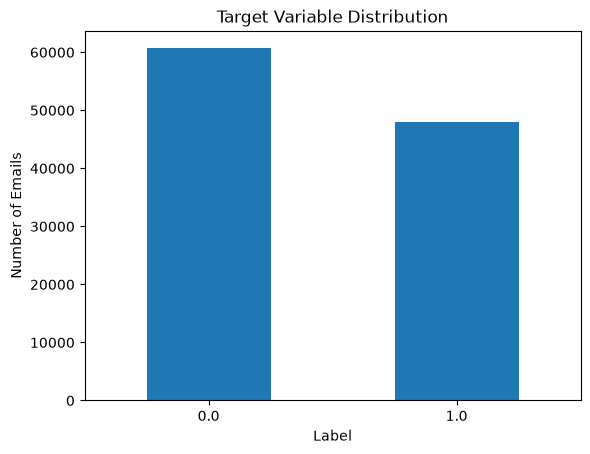

In [9]:
# 1. Identify the available labels
print("Unique labels:")
print(df["label"].unique())

# 2. Count records belonging to each label
print("\nLabel distribution:")
print(df["label"].value_counts(dropna=False))

# 3. Calculate class percentages
print("\nLabel percentages:")
print(
    (df["label"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

# 4. Visualize the distribution
df["label"].value_counts().plot(
    kind="bar",
    title="Target Variable Distribution",
    xlabel="Label",
    ylabel="Number of Emails",
    rot=0
)

In [10]:
# Exclude records with missing labels
labeled_df = df.dropna(subset=["label"])

# Count each class
class_counts = labeled_df["label"].value_counts()

# Calculate the imbalance ratio
imbalance_ratio = class_counts.max() / class_counts.min()

print("Majority class:", class_counts.idxmax())
print("Minority class:", class_counts.idxmin())
print("Imbalance ratio:", round(imbalance_ratio, 2))

Majority class: 0.0
Minority class: 1.0
Imbalance ratio: 1.26


In [11]:
# Verify what the labels actually mean
# Inspect representative records from each class
display(df.loc[df["label"] == 0].head(3))

display(df.loc[df["label"] == 1].head(3))

,sender,sender_domain,receiver,receiver_domain,date,subject,content_types,body,urls,url_count,url_length_max,url_length_avg,url_subdom_max,url_subdom_avg,attachment_count,has_attachments,attachment_types,language,source,label
0,d66e9e64b006d6bca649f1c945129c42c43836872b2ead...,enron.com,35c5a9fb9fba3b8737ed7cef2a87e427a73db4fca85f6b...,enron.com,2001-06-29 09:37:04-05:00,[ORGANIZATION] failover plan.,text/plain,"Hi [NAME], \n\nTonight we are rolling out a n...",NaN,0.0,0.0,0.0,0.0,0.0,0.0,False,NaN,en,trec5,0.0
1,0907d5c64598aa2639154ed4e1556be615669e40052a1f...,enron.com,aa2c35499eae5999bf6080453cc719a891da2bb0c3803d...,enron.com,2001-06-29 08:39:30-05:00,RE: Intranet Site,text/plain,"[NAME] r these new?\tIntranet Site\n\n[NAME],\...",http://eastpower.dev.corp.enron.com/summary/pj...,3.0,60.0,58.0,3.0,3.0,0.0,False,NaN,en,trec5,0.0
2,7c3201a5ff8c5985218f1e3f11e330dc0242bbd28c6c20...,enron.com,a736837579feb601fbf6c0657d3d93689774afa6491bb9...,enron.com;enron.com,2001-06-29 10:35:17-05:00,FW: [ORGANIZATION] Company information,text/plain,"[NAME]/[NAME],\n\nWe are currently trading und...",NaN,0.0,0.0,0.0,0.0,0.0,0.0,False,NaN,en,trec5,0.0


,sender,sender_domain,receiver,receiver_domain,date,subject,content_types,body,urls,url_count,url_length_max,url_length_avg,url_subdom_max,url_subdom_avg,attachment_count,has_attachments,attachment_types,language,source,label
69,4d0f40c9f59d868e917900981a584a77dadd6c0b0a7590...,yahoo.com,ea57021a3519a78f982d2b51888aeda8b0c00706759080...,enron.com,2001-07-04 08:04:55+00:00,ÀÎÅÍ<|SIMBOL|>Ý Ä<|SIMBOL|><|SIMBOL|>å<|SIMBOL...,text/html,<|EMOJI|>FFFFB9<|EMOJI|>FFFFCF<|EMOJI|>FFFFC0<...,http://www.mktadmin.com/mktmail/mkt10/mkt10_ma...,2.0,55.0,50.500000,1.0,1.000000,0.0,False,NaN,en,trec5,1.0
70,e94e94342edaf3434ad28bbf8cc26b4781b403071d8385...,chartertn.net,d3972b9b7c7b6169fc0206e1ebf5397e2c1828a015cd87...,enron.com;exchange.enron.com,2001-07-04 06:16:43-04:00,Hey tehre,text/html,Sa;ve 7_0% ord.ering onl/ine To`day!\nVi!sit o...,"http://www.w3.org/TR/REC-html40""\nhttp://vbusi...",5.0,41.0,37.400000,1.0,1.000000,0.0,False,NaN,en,trec5,1.0
71,641175d23229494cef99743d5b62bf0fdcf61b0b629aa1...,yahoo.co.kr,2ae7baad36968bf9b088a39742aa32aba64aa4bcf015a3...,enron.com,2001-07-04 09:52:26+00:00,ÅëÇÕ<|SIMBOL|><|SIMBOL|><|SIMBOL|>ñ<|SIMBOL|><...,text/html,12-5<|EMOJI|>FFFFBD<|EMOJI|>FFFFB4<|EMOJI|>FFF...,"http://loan2you.co.kr/img/email_img00.gif""\nht...",11.0,92.0,68.363636,1.0,0.636364,0.0,False,NaN,en,trec5,1.0


In [12]:
# Compare target labels across dataset sources
source_label_counts = pd.crosstab(
    df["source"],
    df["label"],
    margins=True
)

display(source_label_counts)

label,0.0,1.0,All
source,,,
trec5,29929,19654,49583
trec6,11208,3797,15005
trec7,19513,24583,44096
All,60650,48034,108684


In [13]:
# Calculate class percentages within each source
source_label_percentages = pd.crosstab(
    df["source"],
    df["label"],
    normalize="index"
) * 100

display(source_label_percentages.round(2))

label,0.0,1.0
source,,
trec5,60.36,39.64
trec6,74.70,25.30
trec7,44.25,55.75


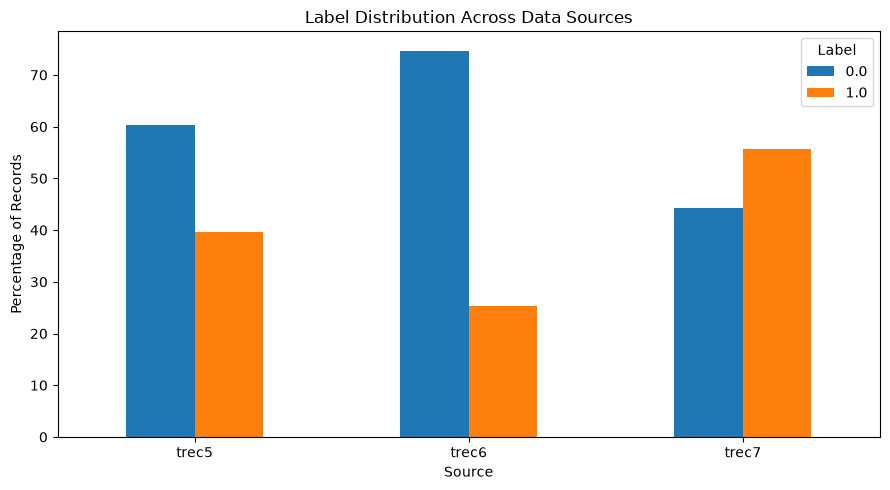

In [15]:
source_label_percentages = (
    pd.crosstab(
        df["source"],
        df["label"],
        normalize="index"
    ) * 100
)

source_label_percentages.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Label Distribution Across Data Sources")
plt.xlabel("Source")
plt.ylabel("Percentage of Records")
plt.xticks(rotation=0)
plt.legend(title="Label")
plt.tight_layout()
plt.show()